In [290]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression
from sklearn.metrics import mean_absolute_error   
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax    
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import cross_validate,StratifiedKFold,GridSearchCV
import statsmodels.api as sm
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder


In [291]:
# 피쳐에 대한 정보입니다
# 이 정보를 가지고 피쳐에 대한 연봉예측 linerRegression 을 구현하시오
# picher_stats_2017.csv

In [292]:
picher = pd.read_csv('data/picher_stats_2017.csv')
picher.head(5)

,선수명,팀명,승,패,세,홀드,블론,경기,선발,이닝,...,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2018),연봉(2017)
0,켈리,SK,16,7,0,0,0,30,30,190.0,...,0.76,0.342,73.7,3.60,6.91,3.69,3.44,6.62,140000,85000
1,소사,LG,11,11,1,0,0,30,29,185.1,...,0.53,0.319,67.1,3.88,6.80,3.52,3.41,6.08,120000,50000
2,양현종,KIA,20,6,0,0,0,31,31,193.1,...,0.79,0.332,72.1,3.44,6.54,3.94,3.82,5.64,230000,150000
3,차우찬,LG,10,7,0,0,0,28,28,175.2,...,1.02,0.298,75.0,3.43,6.11,4.20,4.03,4.63,100000,100000
4,레일리,롯데,13,7,0,0,0,30,30,187.1,...,0.91,0.323,74.1,3.80,6.13,4.36,4.31,4.38,111000,85000


In [293]:
picher.info()
picher.describe()

<class 'pandas.DataFrame'>
RangeIndex: 152 entries, 0 to 151
Data columns (total 22 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   선수명       152 non-null    str    
 1   팀명        152 non-null    str    
 2   승         152 non-null    int64  
 3   패         152 non-null    int64  
 4   세         152 non-null    int64  
 5   홀드        152 non-null    int64  
 6   블론        152 non-null    int64  
 7   경기        152 non-null    int64  
 8   선발        152 non-null    int64  
 9   이닝        152 non-null    float64
 10  삼진/9      152 non-null    float64
 11  볼넷/9      152 non-null    float64
 12  홈런/9      152 non-null    float64
 13  BABIP     152 non-null    float64
 14  LOB%      152 non-null    float64
 15  ERA       152 non-null    float64
 16  RA9-WAR   152 non-null    float64
 17  FIP       152 non-null    float64
 18  kFIP      152 non-null    float64
 19  WAR       152 non-null    float64
 20  연봉(2018)  152 non-null    int64  
 21  연봉(2

,승,패,세,홀드,블론,경기,선발,이닝,삼진/9,볼넷/9,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2018),연봉(2017)
count,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000
mean,3.197368,3.157895,1.473684,2.644737,0.888158,28.848684,6.092105,56.953947,7.049605,4.183289,1.209934,0.340507,68.523026,6.046053,1.056908,5.506842,5.536776,0.665921,18932.236842,16505.263158
std,3.863635,3.130929,4.808860,4.515474,1.633869,19.371502,9.750093,50.297632,2.827552,2.362819,1.017072,0.088985,11.591590,4.166645,1.843708,1.871047,1.981596,1.322205,30940.732924,25046.478092
min,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,35.700000,0.000000,-1.210000,0.730000,-0.690000,-1.010000,2700.000000,2700.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,0.000000,19.900000,5.492500,2.585000,0.690000,0.303750,62.400000,4.082500,-0.092500,4.437500,4.347500,-0.060000,4000.000000,3000.000000
50%,2.000000,2.000000,0.000000,0.000000,0.000000,26.000000,0.000000,43.700000,6.900000,3.750000,1.070000,0.333000,68.250000,5.355000,0.330000,5.210000,5.320000,0.130000,7550.000000,6000.000000
75%,5.000000,6.000000,0.000000,3.000000,1.000000,41.000000,7.000000,80.325000,8.212500,5.262500,1.550000,0.364000,74.525000,7.055000,1.522500,6.392500,6.570000,0.930000,18500.000000,15250.000000
max,20.000000,12.000000,37.000000,24.000000,7.000000,75.000000,31.000000,193.100000,22.500000,18.000000,9.000000,0.833000,100.000000,36.000000,7.280000,18.730000,17.600000,6.620000,230000.000000,150000.000000


In [294]:
picher.head(5)

,선수명,팀명,승,패,세,홀드,블론,경기,선발,이닝,...,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2018),연봉(2017)
0,켈리,SK,16,7,0,0,0,30,30,190.0,...,0.76,0.342,73.7,3.60,6.91,3.69,3.44,6.62,140000,85000
1,소사,LG,11,11,1,0,0,30,29,185.1,...,0.53,0.319,67.1,3.88,6.80,3.52,3.41,6.08,120000,50000
2,양현종,KIA,20,6,0,0,0,31,31,193.1,...,0.79,0.332,72.1,3.44,6.54,3.94,3.82,5.64,230000,150000
3,차우찬,LG,10,7,0,0,0,28,28,175.2,...,1.02,0.298,75.0,3.43,6.11,4.20,4.03,4.63,100000,100000
4,레일리,롯데,13,7,0,0,0,30,30,187.1,...,0.91,0.323,74.1,3.80,6.13,4.36,4.31,4.38,111000,85000


In [295]:
# label = picher['연봉(2018)'].values

# data = picher.iloc[:, 2:].drop(picher.columns[-2], axis=1)
# # label = picher.iloc[:, -2]
# label = picher['연봉(2018)']

# label = picher['연봉(2018)']
# data = picher.iloc[:, 2:].drop(['연봉(2018)'], axis=1)

# data
# label

# 데이터 분리
# picher = picher.rename(columns={'연봉(2018)': 'y'}) # 컬럼명 변경
data = picher[picher.columns.difference(['선수명','팀명','연봉(2018)'])]
team = picher['팀명']
label = picher['연봉(2018)']


In [296]:
team = team.to_numpy().reshape(-1,1)
encoder = OneHotEncoder(sparse_output=False,drop='first', dtype=int)
result = encoder.fit_transform(team)
total_data = np.concatenate((data, result), axis=1)
total_data

array([[ 0.342,  3.6  ,  3.69 , ...,  0.   ,  0.   ,  0.   ],
       [ 0.319,  3.88 ,  3.52 , ...,  0.   ,  0.   ,  0.   ],
       [ 0.332,  3.44 ,  3.94 , ...,  0.   ,  0.   ,  0.   ],
       ...,
       [ 0.382, 11.66 ,  8.03 , ...,  1.   ,  0.   ,  0.   ],
       [ 0.341,  5.77 ,  6.87 , ...,  0.   ,  1.   ,  0.   ],
       [ 0.312,  7.67 ,  7.6  , ...,  0.   ,  0.   ,  0.   ]],
      shape=(152, 27))

In [297]:
train_data, test_data, train_label, test_label = train_test_split(data, label, test_size=0.2, random_state=42)

In [298]:
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [299]:
alpha_list = [0.001,0.01,0.1,1,10,100]

train_score = []
test_score = []
for alpha in alpha_list:
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)

    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)
print('완료') 

완료


In [300]:
train_score = []
test_score = []
cc = [0.001,0.01,0.1,1,10,20,50,100]

for c in cc: 
    lr = LogisticRegression(C=c,max_iter=1000)
    lr.fit(train_scaled,train_label)
    train_score.append(lr.score(train_scaled,train_label))
    test_score.append(lr.score(test_scaled,test_label))

In [301]:
print(data.columns)
print(data.iloc[0])

Index(['BABIP', 'ERA', 'FIP', 'LOB%', 'RA9-WAR', 'WAR', 'kFIP', '경기', '볼넷/9',
       '블론', '삼진/9', '선발', '세', '승', '연봉(2017)', '이닝', '패', '홀드', '홈런/9'],
      dtype='str')
BABIP           0.342
ERA             3.600
FIP             3.690
LOB%           73.700
RA9-WAR         6.910
WAR             6.620
kFIP            3.440
경기             30.000
볼넷/9            2.130
블론              0.000
삼진/9            8.950
선발             30.000
세               0.000
승              16.000
연봉(2017)    85000.000
이닝            190.000
패               7.000
홀드              0.000
홈런/9            0.760
Name: 0, dtype: float64


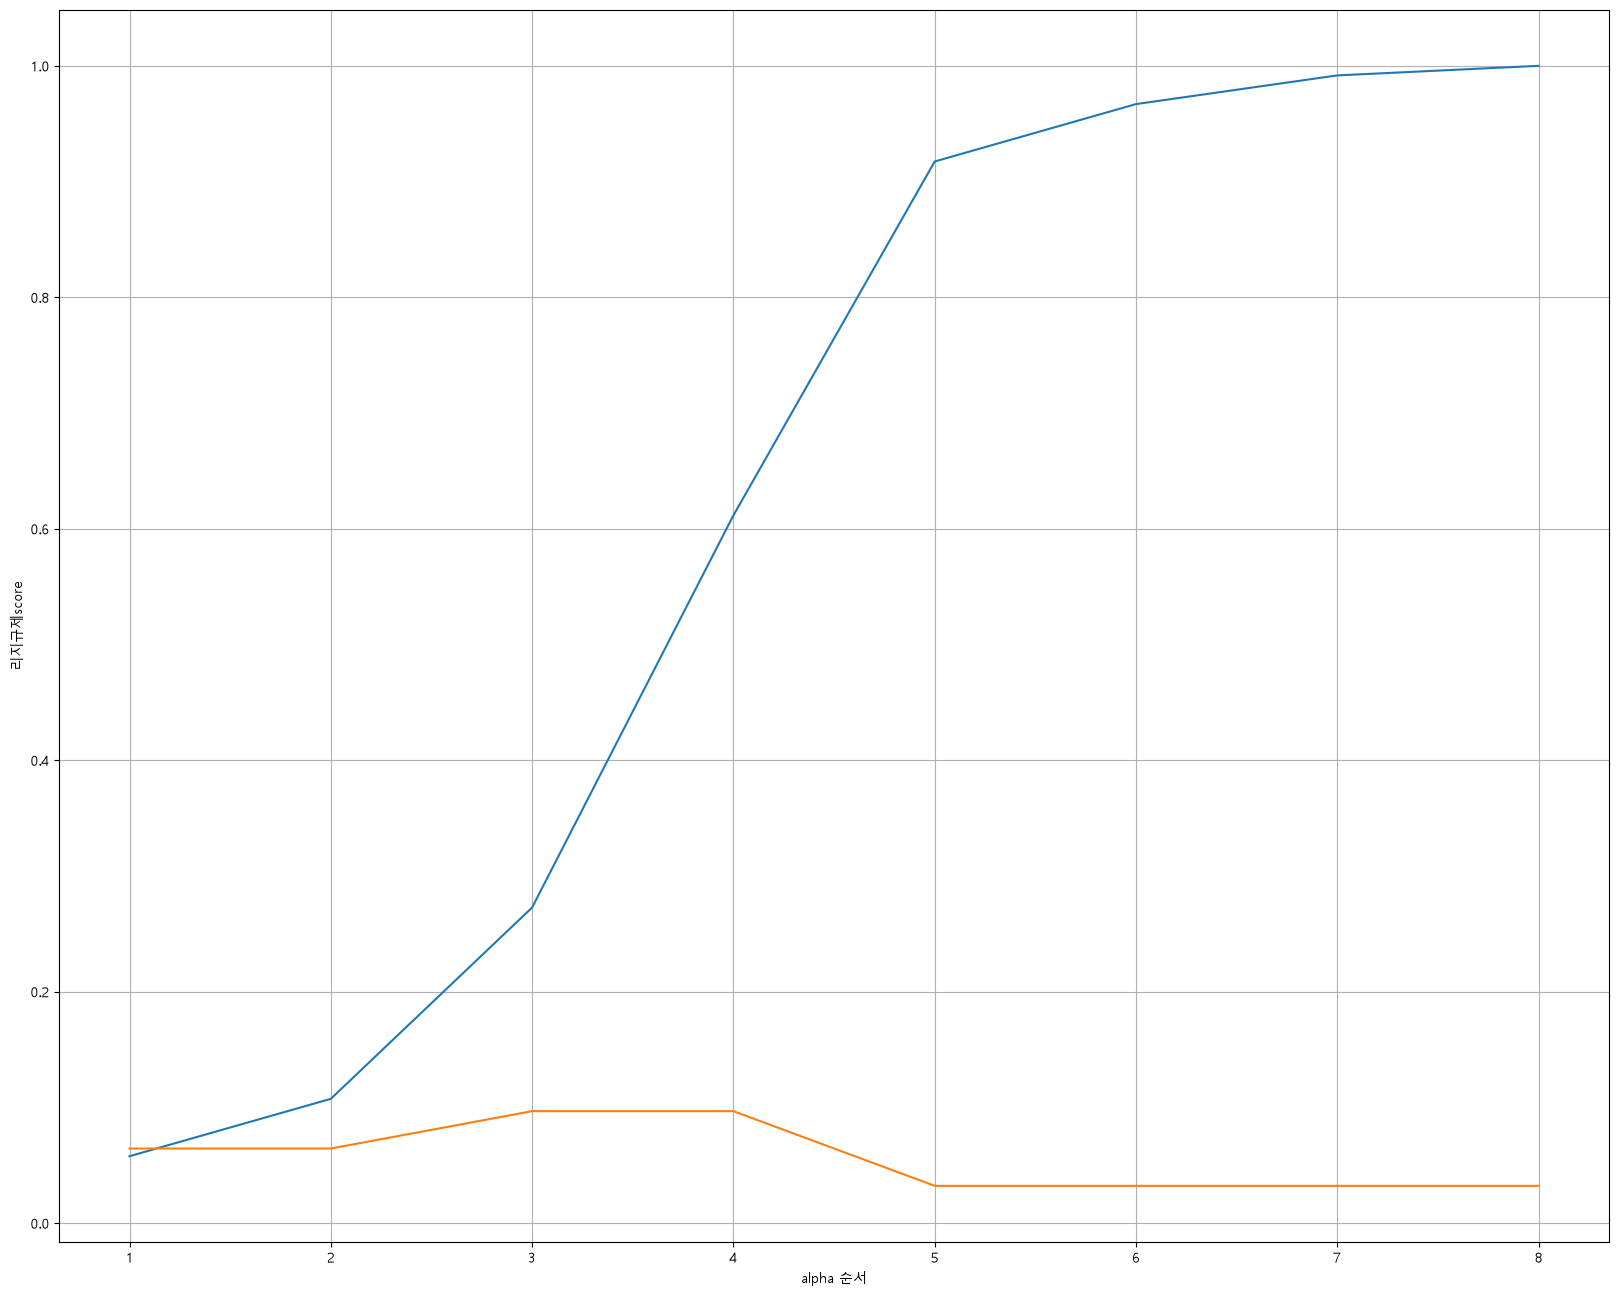

In [302]:
# 선그래프
no_list = [1,2,3,4,5,6,7,8]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.xlabel('alpha 순서')
plt.ylabel('리지규제score')
plt.grid()
plt.show()

In [303]:
ridge = Ridge(alpha=10)
model = ridge.fit(train_scaled,train_label)
# 정확도
score = ridge.score(train_scaled,train_label)
score2 = ridge.score(test_scaled,test_label)
print('train 정확도 : ',score)
print('test 정확도 : ',score2)

train 정확도 :  0.9172010716207589
test 정확도 :  0.8755299362539292


In [304]:
data.columns

Index(['BABIP', 'ERA', 'FIP', 'LOB%', 'RA9-WAR', 'WAR', 'kFIP', '경기', '볼넷/9',
       '블론', '삼진/9', '선발', '세', '승', '연봉(2017)', '이닝', '패', '홀드', '홈런/9'],
      dtype='str')

In [305]:
# pip install statsmodels
# 회귀분석 통계결과표 : P>|t| 통계량의 절대값보다 크거나 같은 값이 나올 확률
# 영향이 0에 가까울 수록 영향이 많이 미친 것이라는 의미
# 영향이 많은 데이터와 적은 데이터를 나누어서 따로 실행해보는 것도 좋음
import statsmodels.api as sm

train_scaled = sm.add_constant(train_scaled)
model = sm.OLS(train_label,train_scaled).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.924
Model:                            OLS   Adj. R-squared:                  0.910
Method:                 Least Squares   F-statistic:                     64.82
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           7.33e-48
Time:                        16:42:24   Log-Likelihood:                -1275.4
No. Observations:                 121   AIC:                             2591.
Df Residuals:                     101   BIC:                             2647.
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.994e+04    910.214     21.910      0.000    1.81e+04    2.17e+04
x1         -1426.0658   1508.920     -0.945      0.347   -4419.358    1567.226
x2           306.5617   2782.269      0.110      0.912   -5212.711    5825.835
x3         -3.685e+04   9.94e+04     -0.371      0.711   -2.34e+05     1.6e+05
x4          -608.9750   1772.873     -0.343      0.732   -4125.877    2907.928
x5          -659.3270   3311.941     -0.199      0.843   -7229.328    5910.674
x6          1.253e+04   2977.444      4.207      0.000    6618.758    1.84e+04
x7          2.787e+04   8.29e+04      0.336      0.737   -1.37e+05    1.92e+05
x8         -3422.0279   3647.550     -0.938      0.350   -1.07e+04    3813.730
x9          4632.3840   6396.429      0.724      0.471   -8056.411    1.73e+04
x10         1065.2349   1426.553      0.747      0.457   -1764.663    3895.133
x11         -418.3394   6628.438     -0.063      0.950   -1.36e+04    1.27e+04
x12        -8453.0994   6349.147     -1.331      0.186    -2.1e+04    4141.901
x13         -234.6394   1433.605     -0.164      0.870   -3078.526    2609.247
x14         4395.5745   2832.591      1.552      0.124   -1223.523       1e+04
x15         2.285e+04   1347.093     16.960      0.000    2.02e+04    2.55e+04
x16         4745.0565   7900.707      0.601      0.549   -1.09e+04    2.04e+04
x17         -181.0170   2115.039     -0.086      0.932   -4376.685    4014.651
x18         -795.8327   1600.092     -0.497      0.620   -3969.984    2378.319
x19         9142.2129   1.68e+04      0.545      0.587   -2.42e+04    4.24e+04
==============================================================================
Omnibus:                       32.192   Durbin-Watson:                   1.801
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              432.406
Skew:                           0.029   Prob(JB):                     1.27e-94
Kurtosis:                      12.261   Cond. No.                         377.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

[Text(0, 0, 'const'),
 Text(1, 0, 'BABIP'),
 Text(2, 0, 'ERA'),
 Text(3, 0, 'FIP'),
 Text(4, 0, 'LOB%'),
 Text(5, 0, 'RA9-WAR'),
 Text(6, 0, 'WAR'),
 Text(7, 0, 'kFIP'),
 Text(8, 0, '경기'),
 Text(9, 0, '볼넷/9'),
 Text(10, 0, '블론'),
 Text(11, 0, '삼진/9'),
 Text(12, 0, '선발'),
 Text(13, 0, '세'),
 Text(14, 0, '승'),
 Text(15, 0, '연봉(2017)'),
 Text(16, 0, '이닝'),
 Text(17, 0, '패'),
 Text(18, 0, '홀드'),
 Text(19, 0, '홈런/9')]

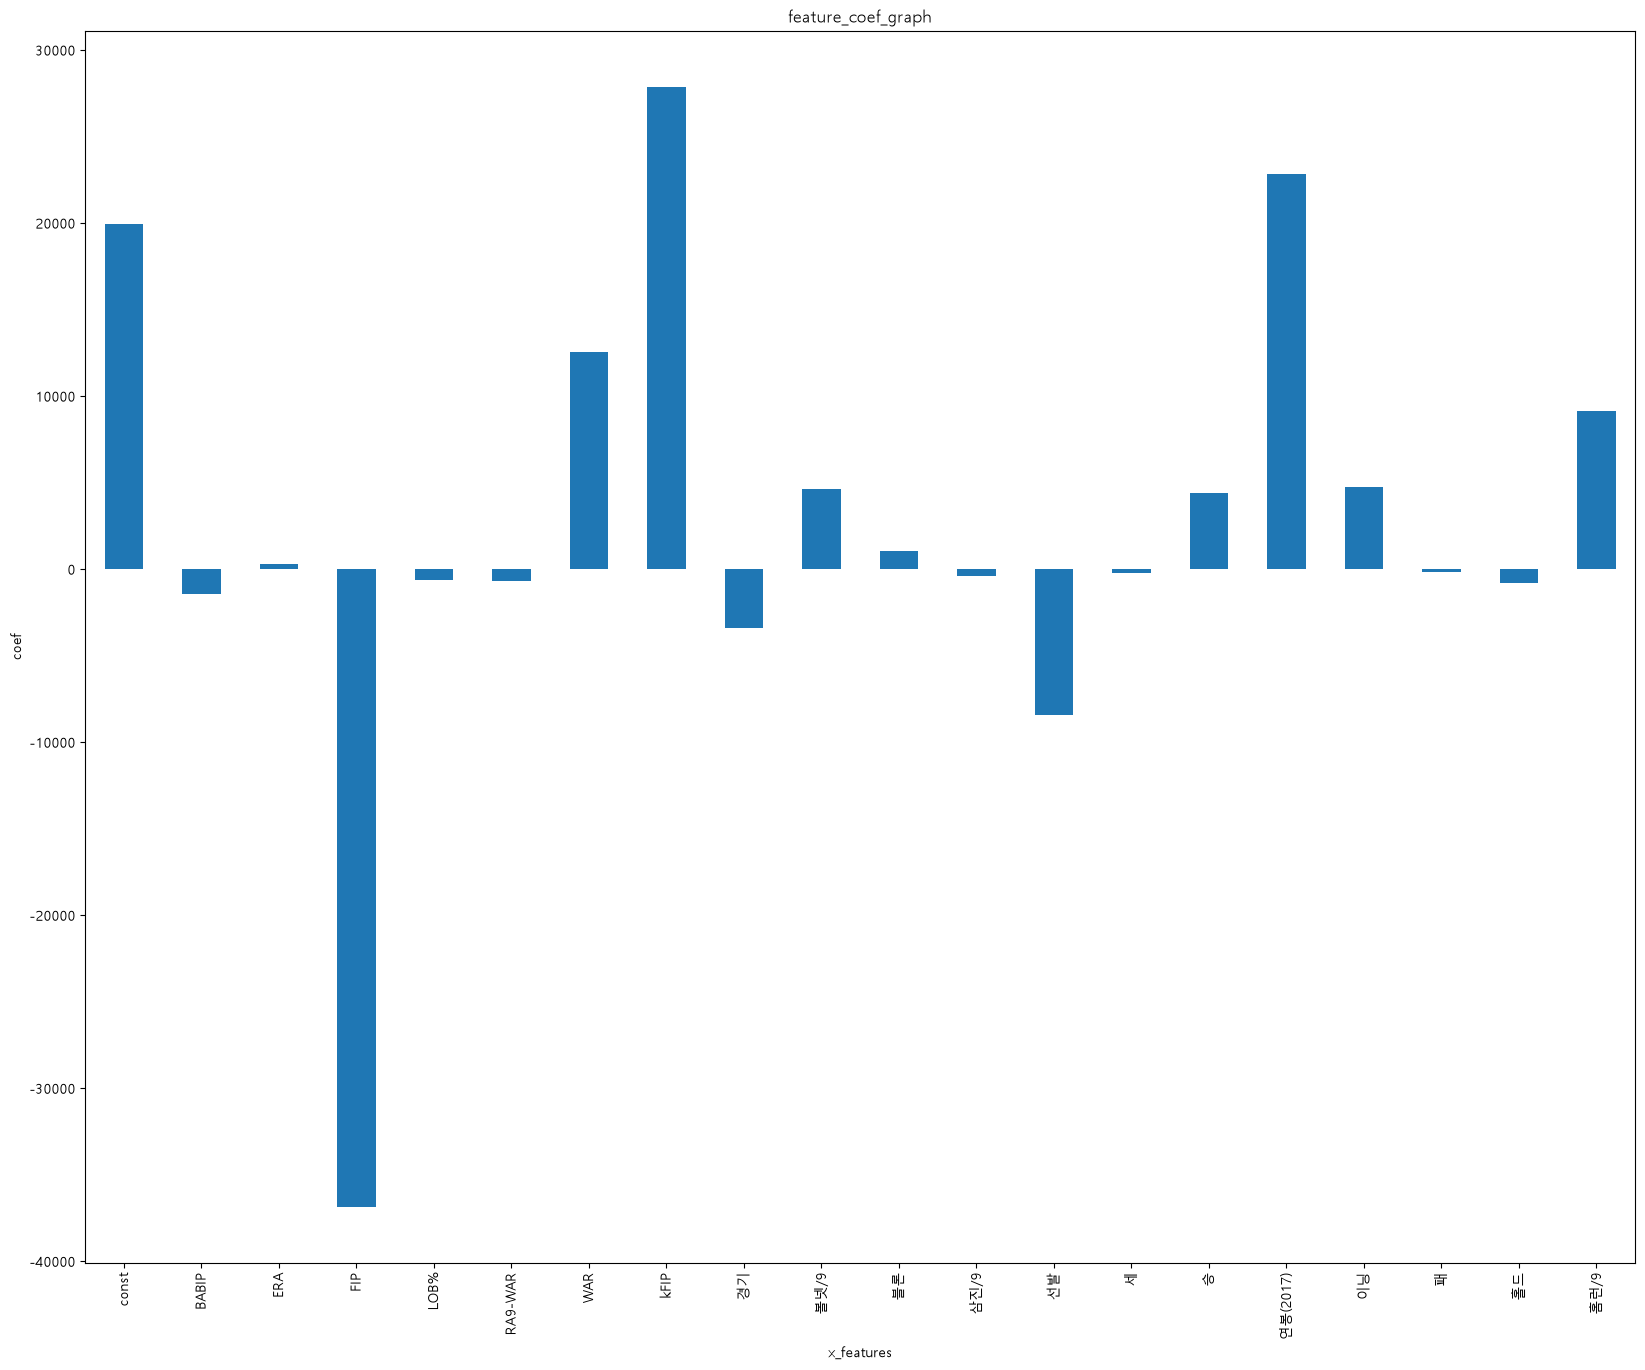

In [306]:
# 결정하는 결과에 영향을 미치는 것을 파악

plt.rcParams['figure.figsize'] = [20, 16]

# 회귀 계수를 리스트로 반환합니다.
coefs = model.params.tolist()
coefs_series = pd.Series(coefs)

# 변수명을 리스트로 반환합니다.
x_labels = model.params.index.tolist()


coefs = model.params.tolist()
coefs_series = pd.Series(coefs)

# 상수항('const')을 맨 앞에 포함하여 변수명 리스트를 만듭니다.
x_labels = ['const'] + data.columns.tolist()

# 회귀 계수를 출력합니다.
ax = coefs_series.plot(kind='bar')
ax.set_xticklabels(x_labels)


# 회귀 계수를 출력합니다.
ax = coefs_series.plot(kind='bar')
ax.set_title('feature_coef_graph')
ax.set_xlabel('x_features')
ax.set_ylabel('coef')
ax.set_xticklabels(x_labels)

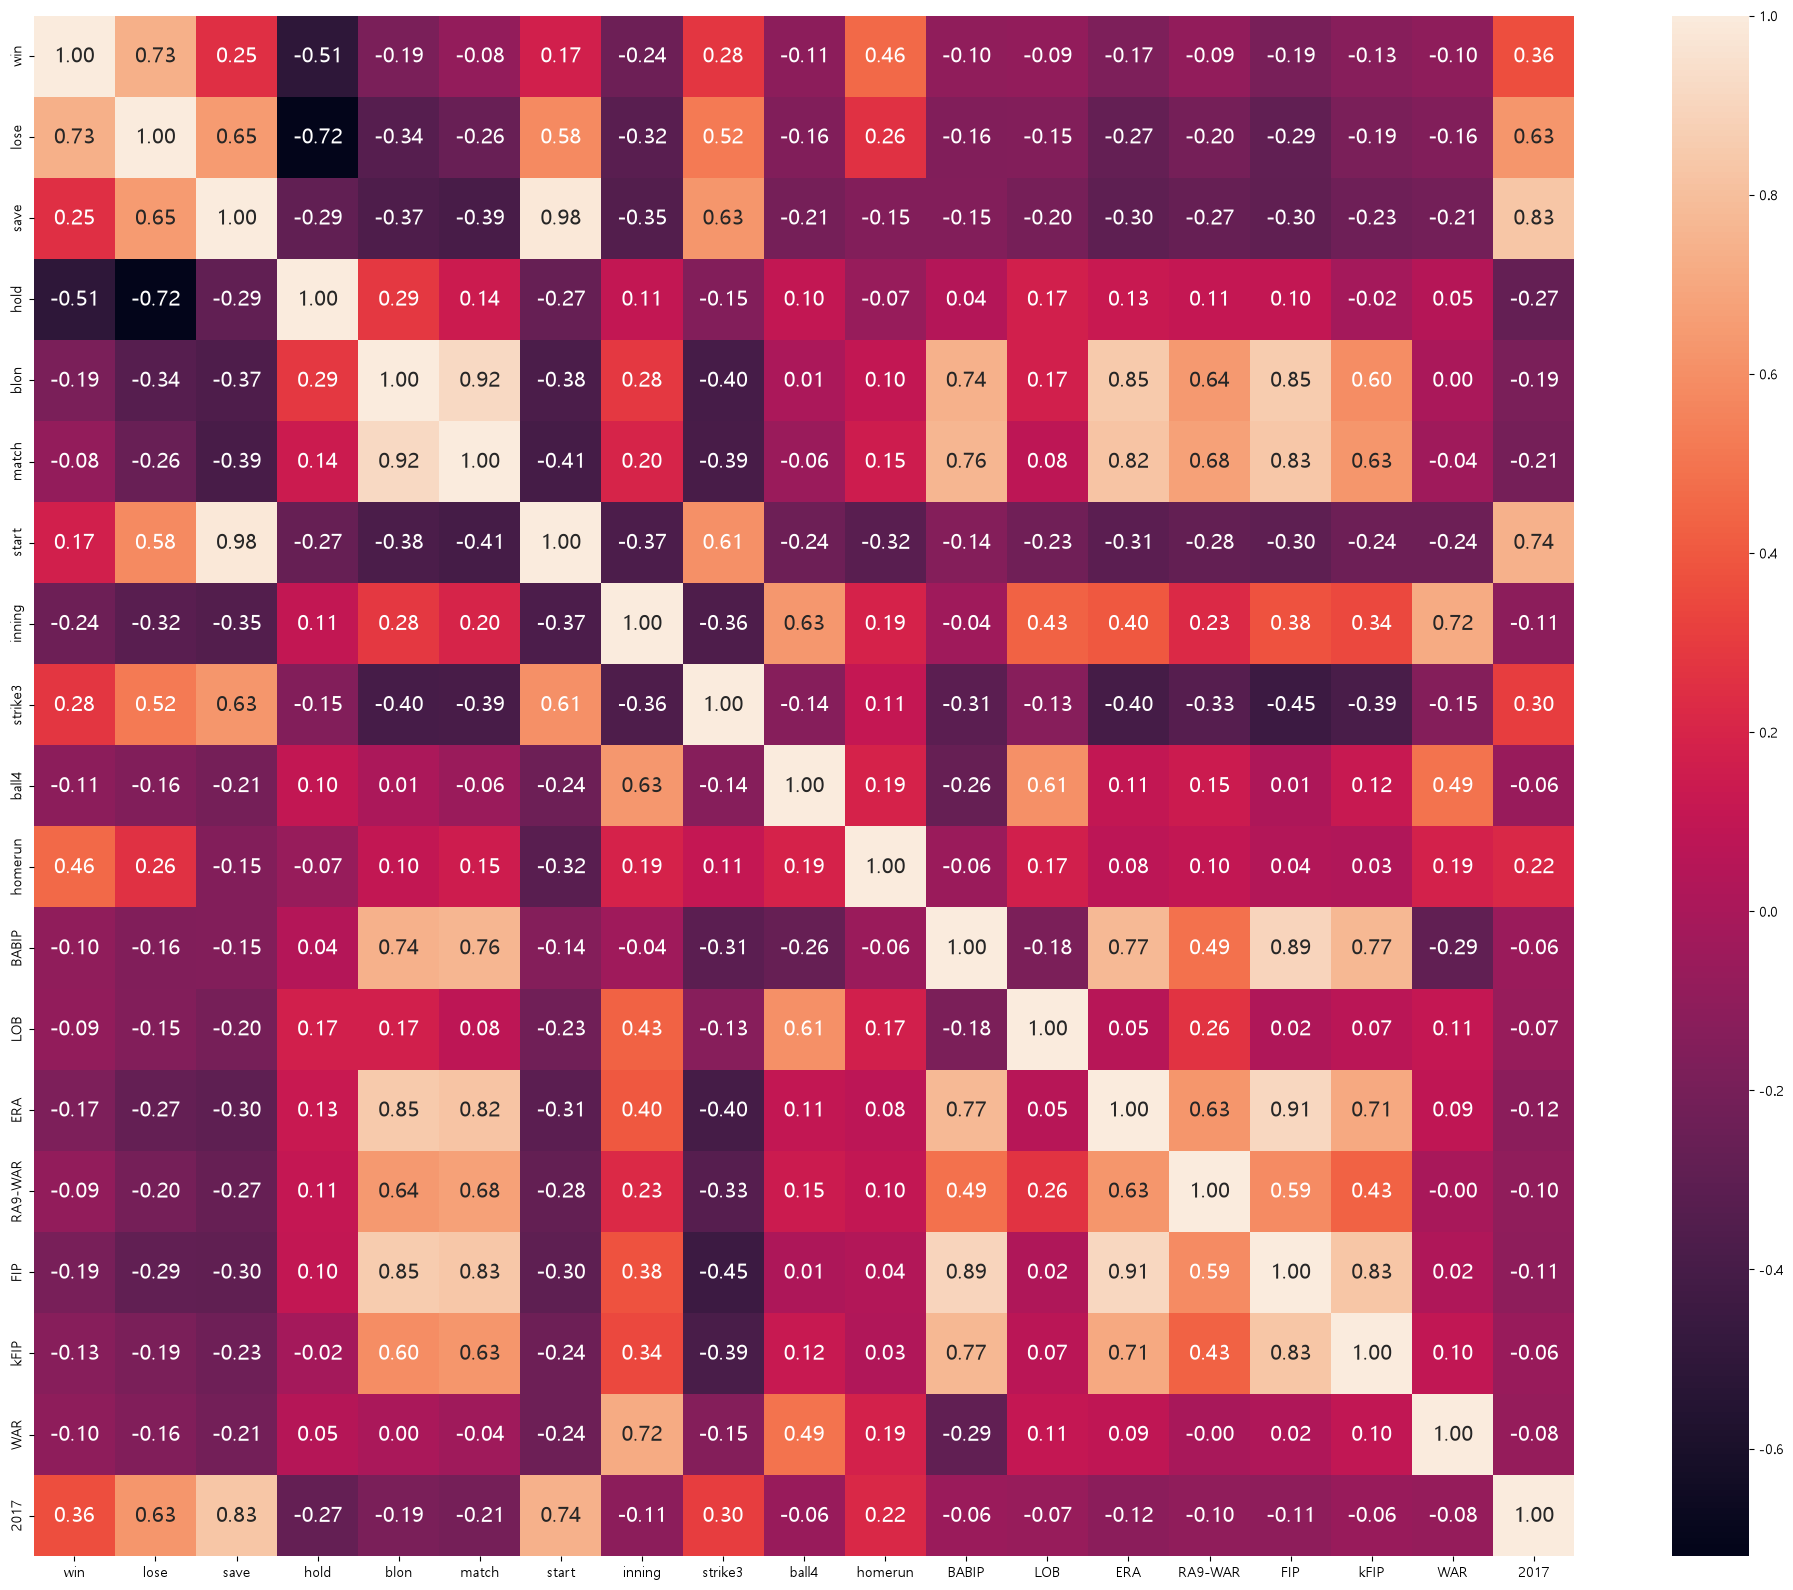

In [307]:
# pip install seaborn
import seaborn as sns

# 피처간의 상관계수 행렬을 계산
corr = picher[data.columns].corr(method='pearson')
show_cols = ['win', 'lose', 'save', 'hold', 'blon', 'match', 'start',
             'inning', 'strike3', 'ball4', 'homerun', 'BABIP', 'LOB',
             'ERA', 'RA9-WAR', 'FIP', 'kFIP', 'WAR', '2017']

# corr 행렬 히트맵을 시각화합니다.
# plt.rc('font', family='NanumGothicOTF')

hm = sns.heatmap(corr.values,
            cbar=True,
            annot=True,
            square=True,
            fmt='.2f',
            annot_kws={'size': 15},
            yticklabels=show_cols,
            xticklabels=show_cols)

plt.tight_layout()
plt.show()

In [308]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
# 다중공선성 확인
# 피처마다의 VIF 계수를 출력합니다.
vif = pd.DataFrame()
vif["VIF Factor"] = [variance_inflation_factor(data.values, i) for i in range(data.shape[1])]
vif["features"] = data.columns
vif.round(1) # 소수점 1자리

,VIF Factor,features
0,3.1,BABIP
1,10.0,ERA
2,12525.2,FIP
3,4.0,LOB%
4,13.4,RA9-WAR
5,10.0,WAR
6,9046.0,kFIP
7,14.2,경기
8,50.7,볼넷/9
9,2.8,블론
